In [6]:
import numpy as np
import jax.numpy as jnp
import jax
from scipy import sparse
import time


import flax.linen as nn
import optax
import optax.tree_utils as otu
from NN_class import MLP
from my_helpers import plot_u_theta, plot_kh
from functools import partial
from Pwp_class import PiecewiseLinearPolynomials

In [34]:
eps0 = 1e-4
def smooth_sign(x, eps = eps0):
    return 2*jax.nn.sigmoid(x/eps)-1

def u0(x):
    return smooth_sign(x-0.4) - smooth_sign(x-0.6)

# Boundary at x=0: [t, 0]
def u1(x):
    return 0

# Boundary at x=1: [t, 1]
def u2(x):
    return 0

# Optimizer Class
class MinMaxOptProb:
    def __init__(self, N_t=10, N_x=10, lr_theta=0.01, hidden_dims=(64, 64, 64), seed=0, sigma=0.1, N_perturb=1000, N_bc=100, 
                 u0=u0, u1=u1, u2=u2, lambda_bc=1, nu=0.001):
        self.pwp = PiecewiseLinearPolynomials(N_t, N_x)
        self.lr_theta = lr_theta
        self.model = MLP(hidden_dims=hidden_dims)
        key = jax.random.PRNGKey(seed)
        self.params = self.model.init(key, jnp.ones((1, 2)))['params']
        # Define optimizer
        self.opt_theta = optax.adam(self.lr_theta)
        self.opt_state_theta = self.opt_theta.init(self.params)
        self.key = jax.random.PRNGKey(seed)
        self.sigma = sigma
        self.N_perturb = N_perturb
        self.N_bc = N_bc
        # Sample points on each boundary
        self.t_bc = jnp.linspace(0, 1, self.N_bc)  # t values for x=0 and x=1 boundaries
        self.x_bc = jnp.linspace(0, 1, self.N_bc)  # x values for t=0 boundary
        self.u0 = u0
        self.u1 = u1
        self.u2 = u2
        self.lambda_bc = lambda_bc
        self.nu = nu

    def compute_res_visc(self, u_quad, u_t, u_x, u_xx):
        # return u_t + u_quad * u_x - self.nu*u_xx
        return u_t + 0.3*u_x - self.nu*u_xx
        
    def compute_res(self, u_quad, u_t, u_x):
        # return u_t + u_quad * u_x  
        return u_t + 0.3*u_x

    def compute_loss_opt_kh_element(self, tri_idx, p_coeffs_all, params):
        """
        Compute losses for all perturbations on a single triangle, compatible with jax.vmap.
    
        Args:
            tri_idx: Index of the triangle.
            p_coeffs_all: Array of shape (N_perturb, 3) of perturbed coefficients.
        Returns:
            losses: Array of shape (N_perturb,) containing loss values for each perturbation.
        """
        # Retrieve precomputed quadrature points and weights
        quad_points = self.pwp.quad_points_tri[tri_idx]  # Shape: (Nq, 2)
        quad_weights = self.pwp.quad_weights_tri[tri_idx]  # Shape: (Nq,)
    
        # Evaluate the neural network and its gradients once for the triangle
        u_quad =self.model.apply({'params': params}, quad_points)  # Shape: (Nq,)
        grad_u = jax.vmap(jax.grad(lambda tx: self.model.apply({'params': params}, tx).squeeze()))(quad_points)  # Shape: (Nq, 2)
        u_t, u_x = grad_u[:, 0], grad_u[:, 1]  # Shapes: (Nq,), (Nq,)
    
        # Compute residual (e.g., u_t + u * u_x), fixed for all perturbations
        residual = self.compute_res(u_quad, u_t, u_x)  # Shape: (Nq,)
    
        # Compute k_h for all perturbations at once
        k_h_quad_all = (
            p_coeffs_all[:, 0][:, None] + 
            p_coeffs_all[:, 1][:, None] * quad_points[:, 0] + 
            p_coeffs_all[:, 2][:, None] * quad_points[:, 1]
        )  # Shape: (N_perturb, Nq)
    
        # Compute integrand for all perturbations using broadcasting
        integrand_all = residual[None, :] * jnp.sign(u_quad[None, :] - k_h_quad_all)  # Shape: (N_perturb, Nq)
    
        # Compute losses by summing over quadrature points for each perturbation
        losses = jnp.sum(quad_weights[None, :] * integrand_all, axis=1)  # Shape: (N_perturb,)
        return losses

    def maximize_kh_vec(self, params, current_key):
        Nt = self.pwp.N_elements
        vertices_all = self.pwp.triangles  # Shape: (Nt, 3, 2)
        
        # Evaluate model on all vertices
        u_values_all = self.model.apply({'params': params}, vertices_all)
        
        # Compute initial coefficients
        A_all = jnp.stack([jnp.ones((Nt, 3)), vertices_all[:, :, 0], vertices_all[:, :, 1]], axis=-1)
        initial_coeffs_all = jnp.linalg.solve(A_all, u_values_all[..., None]).squeeze(-1)
        # print(jnp.einsum('ijk,ik->ij', A_all, initial_coeffs_all)-u_values_all)
    
        # Generate perturbations
        key, current_key = jax.random.split(current_key)
        keys = jax.random.split(key, Nt)
        perturbations_all = jax.vmap(lambda k: self.sigma * jax.random.normal(k, (self.N_perturb, 3)))(keys)
        perturbed_coeffs_all = initial_coeffs_all[:, None, :] + perturbations_all
        # print(perturbed_coeffs_all.shape)
        # Compute losses (assuming compute_loss_tri is defined)
        losses_all = jax.vmap(lambda tri_idx, p_coeffs: 
                              self.compute_loss_opt_kh_element(tri_idx, p_coeffs, params))(jnp.arange(Nt), perturbed_coeffs_all)
        # print(losses_all.shape)
        # Select best coefficients
        best_indices = jnp.argmax(losses_all, axis=1)
        best_coeffs_all = perturbed_coeffs_all[jnp.arange(Nt), best_indices]
        return best_coeffs_all, current_key

    def compute_loss_opt_utheta_int(self, params, p_coeffs):
        # Get quadrature points and weights for this triangle
        quad_points = self.pwp.quad_points  # Shape: (Nt*Nq, 2)
        quad_weights = self.pwp.quad_weights  # Shape: (Nt*Nq,)
    
        # Evaluate neural network and its gradients at quadrature points
        u_quad = self.model.apply({'params': params}, quad_points)  # Shape: (Nt*Nq,)
        grad_u = jax.vmap(jax.grad(lambda tx: self.model.apply({'params': params}, tx).squeeze()))(quad_points)  # Shape: (Nt*Nq, 2)
        u_t, u_x = grad_u[:, 0], grad_u[:, 1]  # Shapes: (Nt*Nq,), (Nt*Nq,)
        # Compute Hessian
        hessian_u = jax.hessian(lambda tx: self.model.apply({'params': params}, tx).squeeze())
        hessians = jax.vmap(hessian_u)(quad_points)  # Shape: (Nt*Nq, 2, 2)
        u_xx = hessians[:, 1, 1]  # Shape: (Nt*Nq,), second derivative w.r.t. x
    
        # Compute the residual (example: u_t + u * u_x for a simple PDE)
        residual = self.compute_res_visc(u_quad, u_t, u_x, u_xx)  # Shape: (Nt*Nq,)
    
        # Compute k_h at quadrature points using the element's coefficients
        # p_coeffs_quad = p_coeffs[self.pwp.element_indices]  # Shape: (Nt*Nq,)
        # # print(f"p_coeffs_quad shape: {p_coeffs_quad.shape}")
        # k_h_quad = p_coeffs_quad[:, 0] + p_coeffs_quad[:, 1] * quad_points[:, 0] + p_coeffs_quad[:, 2] * quad_points[:, 1]  # Shape: (Nt*Nq,)

        # Define the integrand for the loss (example: residual * sign(u - k_h))
        # integrand = residual * jnp.sign(u_quad - k_h_quad)  # Shape: (Nt*Nq,)
        integrand = residual**2
    
        # Integrate over the element using quadrature
        interior_loss = jnp.sum(quad_weights * integrand)  # Scalar
        return interior_loss
        
    def compute_loss_opt_utheta_bc(self, params):
        # --- Boundary Loss ---
        # Boundary at t=0: [0, x]
        tx_t0 = jnp.stack([jnp.zeros_like(self.x_bc), self.x_bc], axis=1)
        u_t0 = self.model.apply({'params': params}, tx_t0)
        bc_t0_loss = jnp.mean((u_t0 - self.u0(self.x_bc))**2)
    
        # Boundary at x=0: [t, 0]
        tx_x0 = jnp.stack([self.t_bc, jnp.zeros_like(self.t_bc)], axis=1)
        u_x0 = self.model.apply({'params': params}, tx_x0)
        bc_x0_loss = jnp.mean((u_x0 - self.u1(self.t_bc))**2)
        # print(f"u1 norm: {jnp.linalg.norm(u_x0)}")
    
        # Boundary at x=1: [t, 1]
        tx_x1 = jnp.stack([self.t_bc, jnp.ones_like(self.t_bc)], axis=1)
        u_x1 = self.model.apply({'params': params}, tx_x1)
        bc_x1_loss = jnp.mean((u_x1 - self.u2(self.t_bc))**2)
        # print(f"u2 norm: {jnp.linalg.norm(u_x1)}")
    
        # Combine boundary losses
        boundary_loss = bc_t0_loss + bc_x0_loss + bc_x1_loss
        # boundary_loss = bc_t0_loss + bc_x0_loss
        return boundary_loss
        
    def compute_loss_opt_utheta(self, params, p_coeffs):
        # --- Total Loss ---
        interior_loss = self.compute_loss_opt_utheta_int(params, p_coeffs)
        boundary_loss = self.compute_loss_opt_utheta_bc(params)
        total_loss = (1-self.lambda_bc) * interior_loss + self.lambda_bc * boundary_loss
        return total_loss

    def test_u_theta_loss(self, params):
        u_quad = self.model.apply({'params': params}, self.pwp.quad_points)
        residual = u_quad - jnp.sin(2*(2*jnp.pi*self.pwp.quad_points[:, 0] + self.pwp.quad_points[:, 1]))
        loss = jnp.sum(residual**2 * self.pwp.quad_weights)
        return loss

    def minimize_u_theta(self, params, p_coeffs, opt_state_theta):
        loss_value, grad_params = jax.value_and_grad(self.compute_loss_opt_utheta, argnums=0)(params, p_coeffs)
        # loss_value, grad_params = jax.value_and_grad(self.test_u_theta_loss)(params)
        updates, opt_state_theta = self.opt_theta.update(grad_params, opt_state_theta)
        params = optax.apply_updates(params, updates)
        return loss_value, params, opt_state_theta

    def train_step(self, iter):
        # maximize k_h
        # maximize_kh_vec = jax.jit(self.maximize_kh_vec)
        # maximize_kh_vec = self.maximize_kh_vec
        # if iter % 1 == 0:
        #     print(f"Before maximize k_h, the loss is {self.compute_loss_opt_utheta_int(self.params, self.pwp.coeffs):.6f}, {self.compute_loss_opt_utheta_bc(self.params):.6f}.")
        # self.pwp.coeffs, self.key = maximize_kh_vec(self.params, self.key)
        # if iter % 1 == 0:
        #     print(f"After maximize k_h, the loss is {self.compute_loss_opt_utheta_int(self.params, self.pwp.coeffs):.6f}, {self.compute_loss_opt_utheta_bc(self.params):.6f}.")
        
        # minimize u_theta
        minimize_u_theta = jax.jit(self.minimize_u_theta)
        # minimize_u_theta = self.minimize_u_theta
        loss_value, self.params, self.opt_state_theta = minimize_u_theta(self.params, self.pwp.coeffs, self.opt_state_theta)
        # return self.compute_loss_opt_utheta(self.params)
        return self.compute_loss_opt_utheta_int(self.params, self.pwp.coeffs), self.compute_loss_opt_utheta_bc(self.params)

        

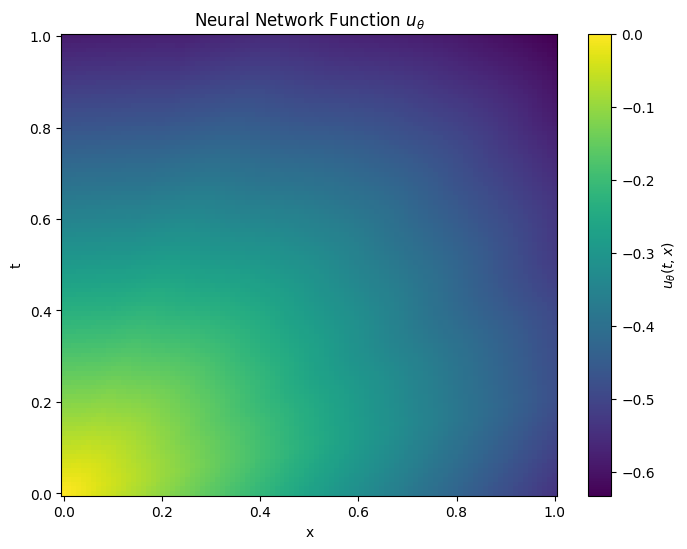

Iteration 0, Loss_int: 32895.976562, Loss_bc: 2.881379
Iteration 10, Loss_int: 187.009521, Loss_bc: 0.208400
Iteration 20, Loss_int: 140.291992, Loss_bc: 0.191204
Iteration 30, Loss_int: 48.167908, Loss_bc: 0.169510
Iteration 40, Loss_int: 46.722931, Loss_bc: 0.177608
Iteration 50, Loss_int: 160.218689, Loss_bc: 0.186801
Iteration 60, Loss_int: 15.801380, Loss_bc: 0.171006
Iteration 70, Loss_int: 30.284475, Loss_bc: 0.147355
Iteration 80, Loss_int: 26.720289, Loss_bc: 0.162130
Iteration 90, Loss_int: 36.715557, Loss_bc: 0.166348
Iteration 100, Loss_int: 37.752930, Loss_bc: 0.217336
Iteration 110, Loss_int: 23.781651, Loss_bc: 0.135745
Iteration 120, Loss_int: 191.924469, Loss_bc: 0.200386
Iteration 130, Loss_int: 32.574368, Loss_bc: 0.258591
Iteration 140, Loss_int: 24.960350, Loss_bc: 0.171242
Iteration 150, Loss_int: 12.379757, Loss_bc: 0.131500
Iteration 160, Loss_int: 7.545511, Loss_bc: 0.129222
Iteration 170, Loss_int: 6.511987, Loss_bc: 0.131255
Iteration 180, Loss_int: 3.913724,

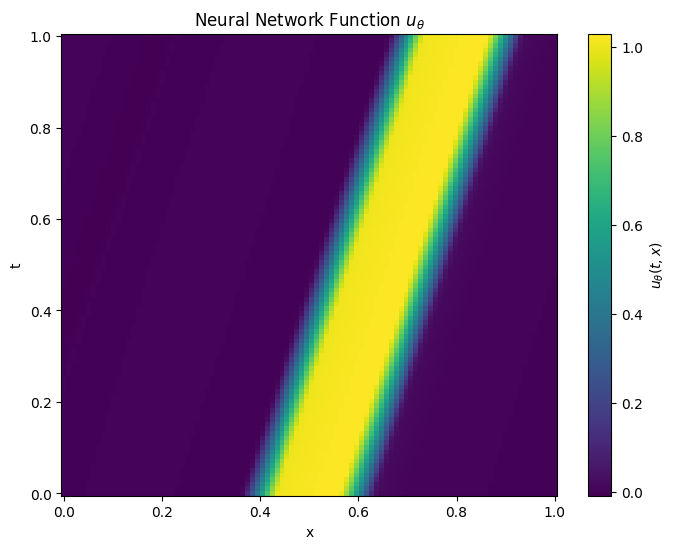

In [25]:
import time
total_time = 0

def u0(x):
    return 0.5*(smooth_sign(x-0.4) - smooth_sign(x-0.6))

# Boundary at x=0: [t, 0]
def u1(x):
    return 0

# Boundary at x=1: [t, 1]
def u2(x):
    return 0

loss_int_histroy = []
loss_bc_histroy = []
# Training Loop
optProb = MinMaxOptProb(
        N_t=30,
        N_x=30,
        lr_theta=0.05,
        hidden_dims=(64, 64, 64),
        seed=0,
        u0=u0, u1=u1, u2=u2,
        lambda_bc=0.99,
    )
num_iterations = 2000

plot_u_theta(optProb.model, optProb.params, M_t=100, M_x=100)
for iter in range(num_iterations):
    start_time = time.perf_counter()  # Start timing
    loss_int, loss_bc = optProb.train_step(iter)
    loss_int_histroy.append(loss_int)
    loss_bc_histroy.append(loss_bc)
    if iter % 10 == 0:
        print(f"Iteration {iter}, Loss_int: {loss_int:.6f}, Loss_bc: {loss_bc:.6f}")
    end_time = time.perf_counter()  # End timing
    total_time += (end_time - start_time)
print(f"Total time: {total_time:.6f} seconds")
print(f"Average time per iteration: {total_time / num_iterations:.9e} seconds")
plot_u_theta(optProb.model, optProb.params, M_t=100, M_x=100)


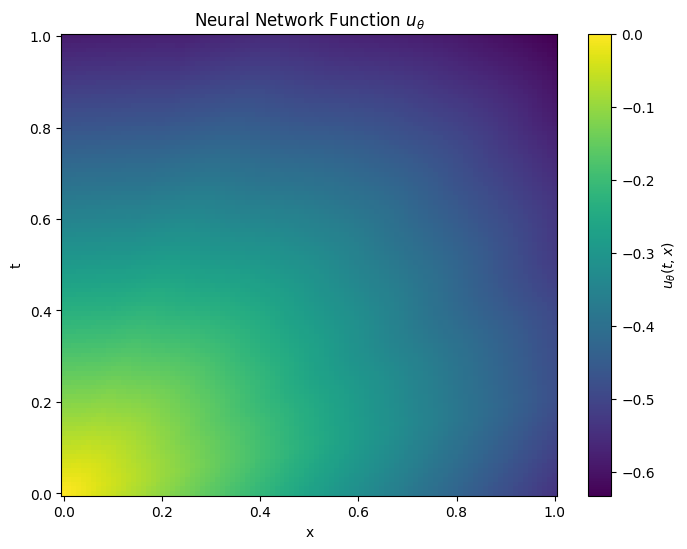

Iteration 0, Loss_int: 32895.976562, Loss_bc: 2.881379
Iteration 10, Loss_int: 187.009521, Loss_bc: 0.208400
Iteration 20, Loss_int: 140.291992, Loss_bc: 0.191204
Iteration 30, Loss_int: 48.167908, Loss_bc: 0.169510
Iteration 40, Loss_int: 46.722931, Loss_bc: 0.177608
Iteration 50, Loss_int: 160.218689, Loss_bc: 0.186801
Iteration 60, Loss_int: 15.801380, Loss_bc: 0.171006
Iteration 70, Loss_int: 30.284475, Loss_bc: 0.147355
Iteration 80, Loss_int: 26.720289, Loss_bc: 0.162130
Iteration 90, Loss_int: 36.715557, Loss_bc: 0.166348


In [ ]:
import time
total_time = 0

def u0(x):
    return 0.5*(smooth_sign(x-0.4) - smooth_sign(x-0.6))

# Boundary at x=0: [t, 0]
def u1(x):
    return 0

# Boundary at x=1: [t, 1]
def u2(x):
    return 0

loss_int_histroy = []
loss_bc_histroy = []
# Training Loop
optProb = MinMaxOptProb(
        N_t=30,
        N_x=30,
        lr_theta=0.05,
        hidden_dims=(64, 64, 64),
        seed=0,
        u0=u0, u1=u1, u2=u2,
        lambda_bc=0.99
    )
num_iterations = 2000

plot_u_theta(optProb.model, optProb.params, M_t=100, M_x=100)
for iter in range(num_iterations):
    start_time = time.perf_counter()  # Start timing
    loss_int, loss_bc = optProb.train_step(iter)
    loss_int_histroy.append(loss_int)
    loss_bc_histroy.append(loss_bc)
    if iter % 10 == 0:
        print(f"Iteration {iter}, Loss_int: {loss_int:.6f}, Loss_bc: {loss_bc:.6f}")
    end_time = time.perf_counter()  # End timing
    total_time += (end_time - start_time)
print(f"Total time: {total_time:.6f} seconds")
print(f"Average time per iteration: {total_time / num_iterations:.9e} seconds")
plot_u_theta(optProb.model, optProb.params, M_t=100, M_x=100)


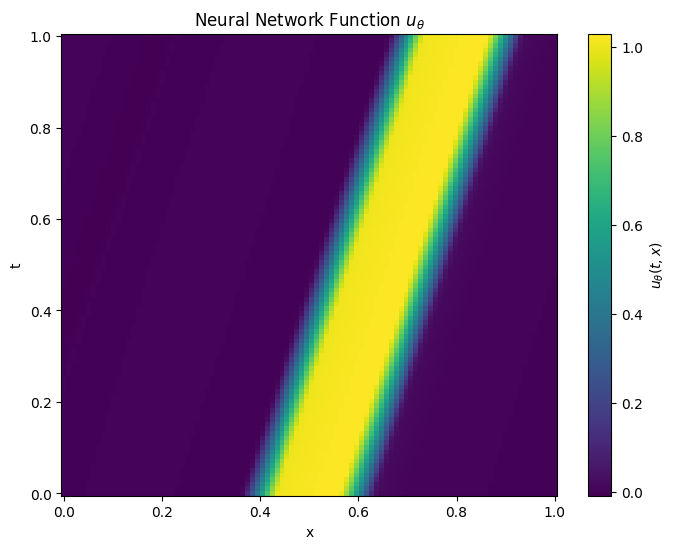

In [26]:
plot_u_theta(optProb.model, optProb.params, M_t=100, M_x=100)


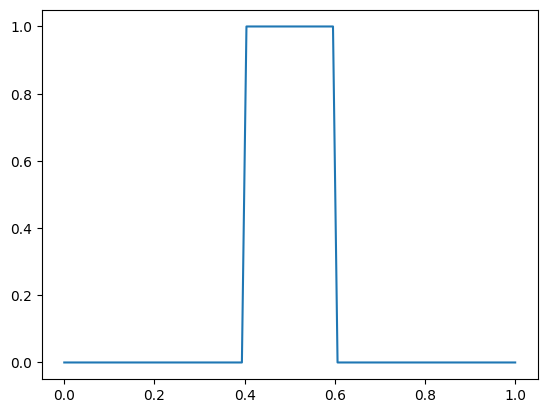

In [20]:
import matplotlib.pyplot as plt

def u0(x):
    return 0.5*(smooth_sign(x-0.4) - smooth_sign(x-0.6))
xx = np.linspace(0,1,100)
yy = u0(xx)

plt.plot(xx, yy)

In [18]:
import jax.numpy as jnp
import matplotlib.pyplot as plt

def plot_at_t1(predict_fn, x_range=(0, 1), num_points=100, filename='plot.eps'):
    """
    Plot the neural network output at t=1 over a range of x values and save as .eps.

    Args:
        predict_fn: A callable that takes a batch of [t, x] inputs and returns outputs.
                    Example: lambda inputs: model.apply({'params': params}, inputs)
        x_range: Tuple (x_min, x_max) specifying the range of x values. Default is (0, 1).
        num_points: Number of points to evaluate and plot. Default is 100.
        filename: Name of the file to save the plot, including '.eps' extension. Default is 'plot.eps'.
    """
    # Generate x values over the specified range
    x = jnp.linspace(x_range[0], x_range[1], num_points)
    
    # Create inputs with t=1 and varying x
    t = jnp.ones_like(x) * 1.0
    inputs = jnp.stack([t, x], axis=1)  # Shape: (num_points, 2)
    
    # Evaluate the neural network on the inputs
    outputs = predict_fn(inputs)  # Shape: (num_points,)
    
    # Create the plot
    plt.figure()
    plt.plot(x, outputs)
    plt.xlabel('x')
    plt.ylabel('u(1, x)')
    plt.title('Neural Network Output at t=1')
    
    # Save the plot in .eps format
    plt.savefig(filename, format='eps')
    # plt.close()  # Close the figure to free memory

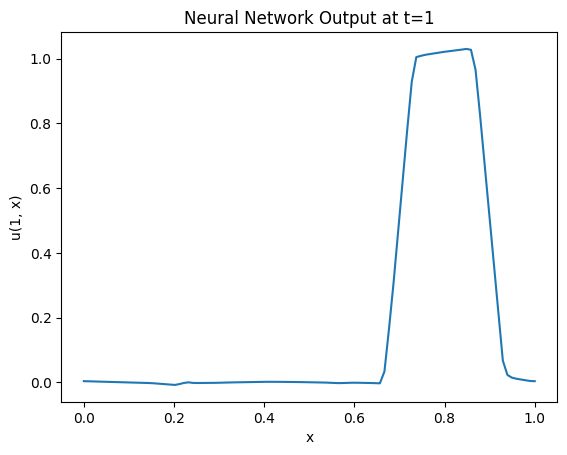

In [27]:
# Assuming 'model' and 'params' are defined (e.g., from a Flax neural network)
predict_fn = lambda inputs: optProb.model.apply({'params': optProb.params}, inputs)

# Call the plotting function
plot_at_t1(predict_fn, x_range=(0, 1), filename='output_at_t1.eps')

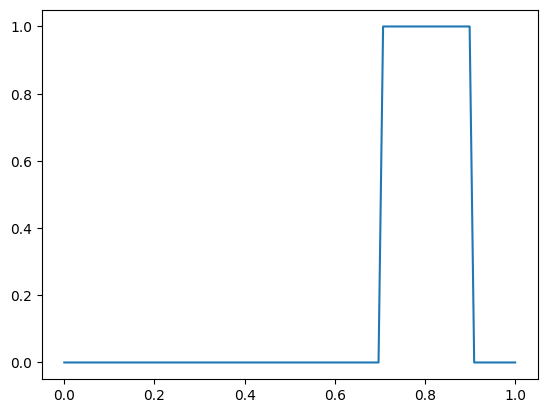

In [28]:
xx = np.linspace(0,1,100)
yy = u0(xx-0.3)

plt.plot(xx, yy)

In [6]:
jnp.array([[[1],[2]],[[3],[4]]]).shape

(2, 2, 1)